# Supplement — Gradient Descent from One to Two Variables

**CSS371: Natural Language Processing**  
**Purpose:** build geometric and computational intuition before neural-network backpropagation  
**Examples:** two one-variable functions and two two-variable functions

This notebook implements Gradient Descent from equations, records every optimization step, and visualizes the trajectory on function curves and surfaces. The plotting code produces SVG directly, so no Matplotlib backend is required.


## Learning outcomes

After completing this notebook, students should be able to:

1. distinguish a parameter, objective function, derivative/gradient, and learning rate;
2. calculate a one-variable Gradient Descent update manually;
3. interpret the sign and magnitude of a derivative;
4. implement Gradient Descent for a vector of two parameters;
5. explain why anisotropic curvature creates zig-zag trajectories;
6. recognize slow convergence, overshooting, divergence, and local-minimum dependence;
7. connect two-variable geometry to high-dimensional neural-network optimization.


## 1. Definition and algorithm

Optimization seeks parameters that minimize an objective or loss function.

### One variable

For $f(w)$, the derivative $f'(w)$ is the local slope. Gradient Descent updates

$$w_{t+1}=w_t-\eta f'(w_t),$$

where $\eta>0$ is the **learning rate**.

- If $f'(w_t)>0$, the curve rises to the right, so the update moves left.
- If $f'(w_t)<0$, the curve falls to the right, so the update moves right.
- If $f'(w_t)=0$, the point is stationary; it may be a minimum, maximum, or saddle-like flat point.

### Multiple variables

For $f(\boldsymbol\theta)$ with $\boldsymbol\theta=(\theta_1,\ldots,\theta_D)$, the gradient is

$$\nabla f(\boldsymbol\theta)=
\begin{bmatrix}
\frac{\partial f}{\partial\theta_1}\\
\vdots\\
\frac{\partial f}{\partial\theta_D}
\end{bmatrix}.$$

The vector update is

$$\boldsymbol\theta_{t+1}=\boldsymbol\theta_t-\eta\nabla f(\boldsymbol\theta_t).$$

The negative gradient is the direction of steepest local decrease under ordinary Euclidean distance. It is a local rule: it does not reveal the global landscape.


In [1]:
import sys
import numpy as np
from IPython.display import SVG, HTML, display

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SVG plots")

def gradient_descent_1d(function, derivative, initial_w, learning_rate, steps):
    w = float(initial_w)
    history = []
    for step in range(steps + 1):
        value = float(function(w))
        gradient = float(derivative(w))
        history.append({"step": step, "w": w, "value": value, "gradient": gradient})
        if step < steps:
            w -= learning_rate * gradient
    return history

def gradient_descent_2d(function, gradient, initial_xy, learning_rate, steps):
    point = np.asarray(initial_xy, dtype=float).copy()
    history = []
    for step in range(steps + 1):
        value = float(function(point[0], point[1]))
        grad = np.asarray(gradient(point[0], point[1]), dtype=float)
        history.append({"step": step, "point": point.copy(), "value": value, "gradient": grad.copy()})
        if step < steps:
            point -= learning_rate * grad
    return history


Python 3.13.15 | NumPy 2.1.3 | SVG plots


## Plot helpers

The next cell contains reusable visualization functions:

- `curve_svg` draws a one-dimensional objective and places numbered optimization points on it.
- `surface_svg` samples a two-dimensional objective on a grid, projects the grid into an isometric wireframe surface, and overlays the optimization path.

For very steep surfaces, a monotonic display transform such as $\log(1+f)$ can make structure visible. The optimization always uses the original function; only the plotted height is transformed.


In [2]:
def curve_svg(function, history, x_range, title, width=820, height=460, samples=280):
    margin = 68
    xs = np.linspace(x_range[0], x_range[1], samples)
    ys = np.asarray([function(x) for x in xs], dtype=float)
    y_pad = 0.08 * max(1e-9, ys.max() - ys.min())
    y_min, y_max = ys.min() - y_pad, ys.max() + y_pad
    sx = lambda x: margin + (x - x_range[0]) / (x_range[1] - x_range[0]) * (width - 2 * margin)
    sy = lambda y: height - margin - (y - y_min) / (y_max - y_min) * (height - 2 * margin)
    curve_points = " ".join(f"{sx(x):.1f},{sy(y):.1f}" for x, y in zip(xs, ys))
    elements = [
        f"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'>",
        "<rect width='100%' height='100%' rx='18' fill='white' stroke='#e2e8f0'/>",
        f"<text x='{width/2}' y='30' text-anchor='middle' font-family='Arial' font-size='21' font-weight='bold'>{title}</text>",
    ]
    for fraction in np.linspace(0, 1, 6):
        x = x_range[0] + fraction * (x_range[1] - x_range[0])
        px = sx(x)
        elements.append(f"<line x1='{px:.1f}' y1='{margin}' x2='{px:.1f}' y2='{height-margin}' stroke='#e2e8f0'/>")
        elements.append(f"<text x='{px:.1f}' y='{height-margin+22}' text-anchor='middle' font-family='Arial' font-size='12'>{x:.1f}</text>")
    for fraction in np.linspace(0, 1, 5):
        y = y_min + fraction * (y_max - y_min)
        py = sy(y)
        elements.append(f"<line x1='{margin}' y1='{py:.1f}' x2='{width-margin}' y2='{py:.1f}' stroke='#e2e8f0'/>")
        elements.append(f"<text x='{margin-10}' y='{py+4:.1f}' text-anchor='end' font-family='Arial' font-size='12'>{y:.2f}</text>")
    elements.append(f"<polyline points='{curve_points}' fill='none' stroke='#0f766e' stroke-width='4'/>")
    path = history if len(history) <= 30 else history[::max(1, len(history)//25)] + [history[-1]]
    path_points = " ".join(f"{sx(h['w']):.1f},{sy(h['value']):.1f}" for h in path)
    elements.append(f"<polyline points='{path_points}' fill='none' stroke='#f97316' stroke-width='2.5' stroke-dasharray='6 4'/>")
    for index, item in enumerate(path):
        color = '#7c3aed' if index == 0 else ('#dc2626' if index == len(path)-1 else '#f97316')
        radius = 7 if index in (0, len(path)-1) else 4.5
        elements.append(f"<circle cx='{sx(item['w']):.1f}' cy='{sy(item['value']):.1f}' r='{radius}' fill='{color}' stroke='white' stroke-width='1.5'/>")
    elements += [
        f"<text x='{width/2}' y='{height-12}' text-anchor='middle' font-family='Arial' font-size='15'>parameter w</text>",
        f"<text x='18' y='{height/2}' text-anchor='middle' font-family='Arial' font-size='15' transform='rotate(-90 18 {height/2})'>objective f(w)</text>",
        "<circle cx='675' cy='58' r='6' fill='#7c3aed'/><text x='688' y='63' font-family='Arial' font-size='13'>start</text>",
        "<circle cx='743' cy='58' r='6' fill='#dc2626'/><text x='756' y='63' font-family='Arial' font-size='13'>final</text>",
        "</svg>",
    ]
    return "".join(elements)

def surface_svg(function, history, x_range, y_range, title, z_transform=lambda z: z,
                width=900, height=600, grid_size=25):
    xs = np.linspace(*x_range, grid_size)
    ys = np.linspace(*y_range, grid_size)
    raw_z = np.array([[function(x, y) for y in ys] for x in xs], dtype=float)
    shown_z = np.asarray(z_transform(raw_z), dtype=float)
    z_min, z_max = shown_z.min(), shown_z.max()
    def project(x, y, z):
        xn = (x - x_range[0]) / (x_range[1] - x_range[0])
        yn = (y - y_range[0]) / (y_range[1] - y_range[0])
        zn = (z_transform(np.asarray(z)) - z_min) / max(1e-12, z_max - z_min)
        u = width / 2 + (xn - yn) * 290
        v = 470 - (xn + yn) * 105 - zn * 255
        return float(u), float(v)
    elements = [
        f"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'>",
        "<rect width='100%' height='100%' rx='18' fill='white' stroke='#e2e8f0'/>",
        f"<text x='{width/2}' y='30' text-anchor='middle' font-family='Arial' font-size='21' font-weight='bold'>{title}</text>",
    ]
    for i, x in enumerate(xs):
        points = " ".join(f"{project(x, y, function(x,y))[0]:.1f},{project(x, y, function(x,y))[1]:.1f}" for y in ys)
        opacity = 0.32 + 0.35 * i / max(1, grid_size-1)
        elements.append(f"<polyline points='{points}' fill='none' stroke='#2563eb' stroke-width='1.1' stroke-opacity='{opacity:.2f}'/>")
    for j, y in enumerate(ys):
        points = " ".join(f"{project(x, y, function(x,y))[0]:.1f},{project(x, y, function(x,y))[1]:.1f}" for x in xs)
        opacity = 0.32 + 0.35 * j / max(1, grid_size-1)
        elements.append(f"<polyline points='{points}' fill='none' stroke='#0f766e' stroke-width='1.1' stroke-opacity='{opacity:.2f}'/>")
    sampled = history if len(history) <= 45 else history[::max(1, len(history)//42)] + [history[-1]]
    projected = [project(h['point'][0], h['point'][1], h['value']) for h in sampled]
    path_points = " ".join(f"{u:.1f},{v:.1f}" for u, v in projected)
    elements.append(f"<polyline points='{path_points}' fill='none' stroke='#f97316' stroke-width='4' stroke-linejoin='round'/>")
    for index, (u, v) in enumerate(projected):
        color = '#7c3aed' if index == 0 else ('#dc2626' if index == len(projected)-1 else '#f97316')
        radius = 7 if index in (0, len(projected)-1) else 3.5
        elements.append(f"<circle cx='{u:.1f}' cy='{v:.1f}' r='{radius}' fill='{color}' stroke='white' stroke-width='1.3'/>")
    elements += [
        "<text x='720' y='520' font-family='Arial' font-size='15'>x-axis</text>",
        "<text x='145' y='520' font-family='Arial' font-size='15'>y-axis</text>",
        "<text x='42' y='105' font-family='Arial' font-size='15' transform='rotate(-62 42 105)'>surface height f(x,y)</text>",
        "<circle cx='730' cy='62' r='6' fill='#7c3aed'/><text x='743' y='67' font-family='Arial' font-size='13'>start</text>",
        "<circle cx='798' cy='62' r='6' fill='#dc2626'/><text x='811' y='67' font-family='Arial' font-size='13'>final</text>",
        "</svg>",
    ]
    return "".join(elements)


# Part I — One variable

## Example 1: convex quadratic bowl

Consider

$$f(w)=(w-3)^2+1.$$

Its derivative and second derivative are

$$f'(w)=2(w-3),\qquad f''(w)=2>0.$$

Because the curvature is positive everywhere, the function is strictly convex and has one global minimum:

$$w^*=3,\qquad f(w^*)=1.$$

With learning rate $\eta$, the distance from the minimum follows

$$w_{t+1}-3=(1-2\eta)(w_t-3).$$

Therefore:

- $0<\eta<0.5$: monotonic convergence;
- $0.5<\eta<1$: oscillating but convergent;
- $\eta=1$: no contraction in distance;
- $\eta>1$: divergence.


step t,wₜ,f(wₜ),f′(wₜ),−ηf′(wₜ),wₜ₊₁
0,-4.000000,50.000000,-14.000000,2.100000,-1.900000
1,-1.900000,25.010000,-9.800000,1.470000,-0.430000
2,-0.430000,12.764900,-6.860000,1.029000,0.599000
3,0.599000,6.764801,-4.802000,0.720300,1.319300
4,1.319300,3.824752,-3.361400,0.504210,1.823510
5,1.823510,2.384129,-2.352980,0.352947,2.176457
6,2.176457,1.678223,-1.647086,0.247063,2.423520
7,2.423520,1.332329,-1.152960,0.172944,2.596464
8,2.596464,1.162841,-0.807072,0.121061,2.717525
9,2.717525,1.079792,-0.564950,0.084743,2.802267


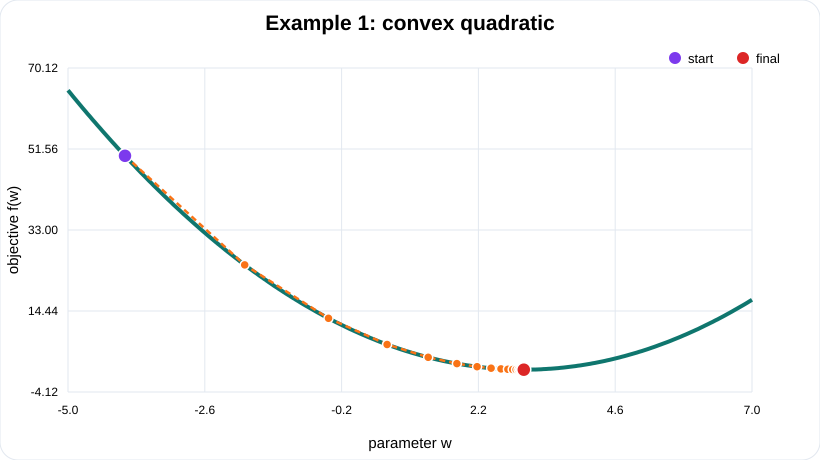

In [3]:
quadratic = lambda w: (w - 3.0) ** 2 + 1.0
quadratic_gradient = lambda w: 2.0 * (w - 3.0)

quadratic_history = gradient_descent_1d(
    quadratic, quadratic_gradient, initial_w=-4.0, learning_rate=0.15, steps=22
)
learning_rate = 0.15
rows = []
for index, item in enumerate(quadratic_history):
    update = -learning_rate * item['gradient'] if index < len(quadratic_history) - 1 else np.nan
    next_w = quadratic_history[index + 1]['w'] if index < len(quadratic_history) - 1 else np.nan
    update_text = f"{update:.6f}" if np.isfinite(update) else "—"
    next_text = f"{next_w:.6f}" if np.isfinite(next_w) else "—"
    rows.append(
        f"<tr><td style='padding:6px;border:1px solid #cbd5e1;text-align:center'>{item['step']}</td>"
        f"<td style='padding:6px;border:1px solid #cbd5e1;text-align:right'>{item['w']:.6f}</td>"
        f"<td style='padding:6px;border:1px solid #cbd5e1;text-align:right'>{item['value']:.6f}</td>"
        f"<td style='padding:6px;border:1px solid #cbd5e1;text-align:right'>{item['gradient']:.6f}</td>"
        f"<td style='padding:6px;border:1px solid #cbd5e1;text-align:right'>{update_text}</td>"
        f"<td style='padding:6px;border:1px solid #cbd5e1;text-align:right'>{next_text}</td></tr>"
    )
table = """
<div style='max-height:430px; overflow:auto; width:fit-content'>
<table style='border-collapse:collapse; font-family:Arial; font-size:14px; min-width:720px'>
<caption style='caption-side:top; text-align:left; font-weight:bold; font-size:16px; padding:8px 0'>
Gradient Descent updates (η = 0.15)</caption>
<thead><tr style='background:#e0f2fe'>
<th style='padding:7px;border:1px solid #94a3b8'>step t</th>
<th style='padding:7px;border:1px solid #94a3b8'>wₜ</th>
<th style='padding:7px;border:1px solid #94a3b8'>f(wₜ)</th>
<th style='padding:7px;border:1px solid #94a3b8'>f′(wₜ)</th>
<th style='padding:7px;border:1px solid #94a3b8'>−ηf′(wₜ)</th>
<th style='padding:7px;border:1px solid #94a3b8'>wₜ₊₁</th>
</tr></thead><tbody>""" + "".join(rows) + "</tbody></table></div>"
display(HTML(table))
display(SVG(curve_svg(quadratic, quadratic_history, (-5, 7), "Example 1: convex quadratic")))


### Learning-rate comparison

The function is unchanged; only $\eta$ changes. Predict which run is slow, monotonic, oscillating, or divergent before executing.


In [4]:
for rate in [0.03, 0.30, 0.75, 1.05]:
    run = gradient_descent_1d(quadratic, quadratic_gradient, -4.0, rate, 15)
    values = [item['value'] for item in run]
    status = "decreased" if values[-1] < values[0] else "increased/diverged"
    print(f"eta={rate:4.2f} final_w={run[-1]['w']:12.4f} final_f={values[-1]:14.4f} {status}")


eta=0.03 final_w=      0.2330 final_f=        8.6565 decreased
eta=0.30 final_w=      3.0000 final_f=        1.0000 decreased
eta=0.75 final_w=      3.0002 final_f=        1.0000 decreased
eta=1.05 final_w=     32.2407 final_f=      856.0207 increased/diverged


## Example 2: non-convex double well

Consider

$$f(w)=\frac{1}{4}w^4-w^2+0.2w,$$

with derivative

$$f'(w)=w^3-2w+0.2.$$

This function is non-convex and contains multiple stationary points. The initial position can determine which local basin Gradient Descent reaches. A zero gradient does not by itself identify whether a stationary point is a minimum or maximum; curvature or nearby function values must also be checked.


left start  -> {'step': 35, 'w': -1.4617862726361393, 'value': -1.2876773875262257, 'gradient': -2.922531858184918e-07}
right start -> {'step': 35, 'w': 1.3612808408590262, 'value': -0.7223478662846528, 'gradient': 8.143599288967796e-06}


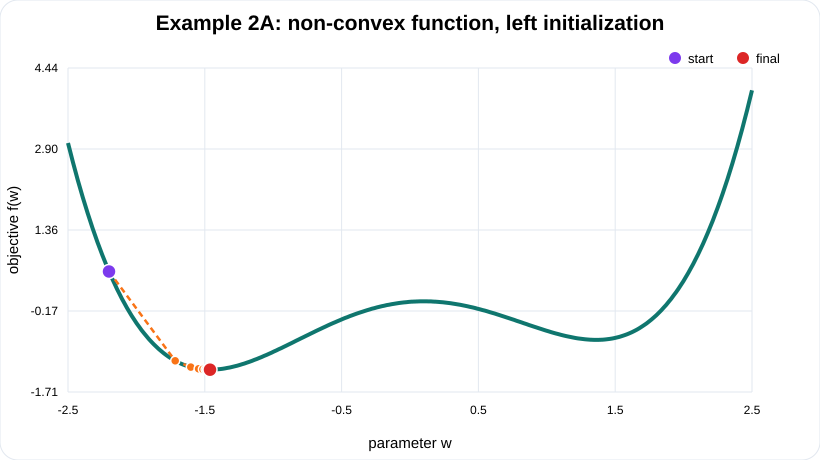

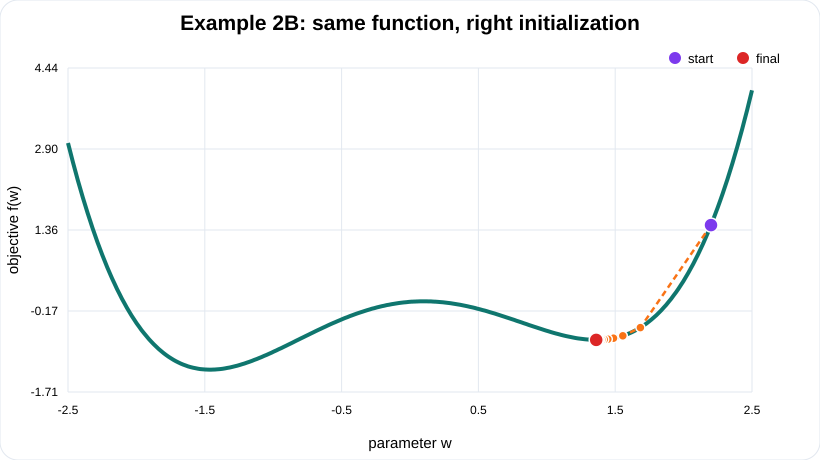

In [5]:
double_well = lambda w: 0.25 * w**4 - w**2 + 0.2 * w
double_well_gradient = lambda w: w**3 - 2*w + 0.2

left_history = gradient_descent_1d(double_well, double_well_gradient, -2.2, 0.08, 35)
right_history = gradient_descent_1d(double_well, double_well_gradient, 2.2, 0.08, 35)
print("left start  ->", left_history[-1])
print("right start ->", right_history[-1])
display(SVG(curve_svg(double_well, left_history, (-2.5, 2.5), "Example 2A: non-convex function, left initialization")))
display(SVG(curve_svg(double_well, right_history, (-2.5, 2.5), "Example 2B: same function, right initialization")))


### Lesson from the one-variable cases

- Convexity can provide a unique global target.
- Non-convexity makes initialization important.
- Gradient Descent uses local slope and does not compare all possible minima.
- A learning rate that works on one curvature scale may fail on another.
- Neural-network loss functions are high-dimensional and generally non-convex, so these simple curves are intuition-building analogies rather than complete models.


# Part II — Two variables

## Example 3: anisotropic elliptical bowl

Consider

$$f(x,y)=(x-2)^2+6(y+1)^2.$$

The gradient is

$$\nabla f(x,y)=
\begin{bmatrix}
2(x-2)\\
12(y+1)
\end{bmatrix}.$$

The minimum is $(x^*,y^*)=(2,-1)$. Curvature is six times stronger in the $y$ direction than in the $x$ direction. With a single learning rate, updates may correct $y$ aggressively while making slower progress along $x$, producing a zig-zag path in narrow valleys.


step= 0 x= -3.5000 y=  3.0000 f=  126.2500 grad=[-11.  48.]
step= 1 x= -2.1800 y= -2.7600 f=   36.0580 grad=[ -8.36 -21.12]
step= 2 x= -1.1768 y= -0.2256 f=   13.6902 grad=[-6.3536  9.2928]
step= 3 x= -0.4144 y= -1.3407 f=    6.5258 grad=[-4.828736 -4.088832]
step= 4 x=  0.1651 y= -0.8501 f=    3.5018 grad=[-3.66983936  1.79908608]
final: {'step': 32, 'point': array([ 1.99915589, -1.        ]), 'value': 7.125170890671491e-07, 'gradient': array([-1.68821455e-03,  1.86950455e-10])}


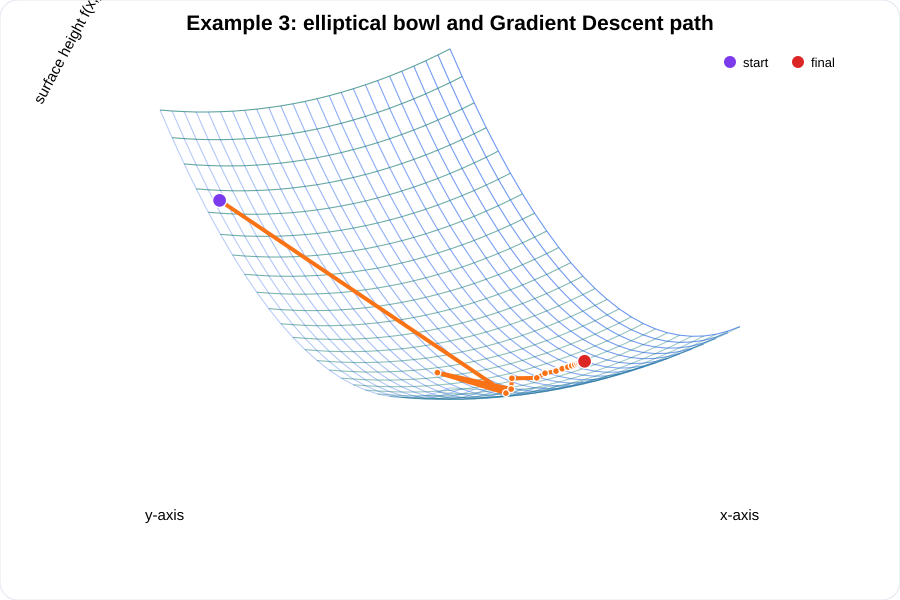

In [6]:
elliptical = lambda x, y: (x - 2.0)**2 + 6.0 * (y + 1.0)**2
elliptical_gradient = lambda x, y: np.array([2.0 * (x - 2.0), 12.0 * (y + 1.0)])

elliptical_history = gradient_descent_2d(
    elliptical, elliptical_gradient, initial_xy=(-3.5, 3.0), learning_rate=0.12, steps=32
)
for item in elliptical_history[:5]:
    x, y = item['point']
    print(f"step={item['step']:2d} x={x:8.4f} y={y:8.4f} f={item['value']:10.4f} grad={item['gradient']}")
print("final:", elliptical_history[-1])
display(SVG(surface_svg(
    elliptical, elliptical_history, (-4, 4), (-3, 4),
    "Example 3: elliptical bowl and Gradient Descent path"
)))


### Partial derivatives as directional sensitivities

Holding $y$ fixed, $\partial f/\partial x$ describes the local change along the $x$ axis. Holding $x$ fixed, $\partial f/\partial y$ describes change along the $y$ axis. The gradient combines both simultaneous sensitivities.

The update is componentwise:

$$x_{t+1}=x_t-\eta\frac{\partial f}{\partial x},\qquad
y_{t+1}=y_t-\eta\frac{\partial f}{\partial y}.$$

The surface plot uses height for $f(x,y)$ and overlays the parameter path in orange. Purple is the starting point; red is the final point.


## Example 4: Rosenbrock function

The Rosenbrock function is a classic optimization test:

$$f(x,y)=(1-x)^2+100(y-x^2)^2.$$

Its gradient is

$$\frac{\partial f}{\partial x}=-2(1-x)-400x(y-x^2),$$
$$\frac{\partial f}{\partial y}=200(y-x^2).$$

The global minimum is $(1,1)$ with value 0, but the function contains a long, narrow, curved valley. Plain Gradient Descent can spend many small steps changing direction inside the valley. This example motivates momentum, adaptive learning rates, normalization, and better-conditioned parameterizations.


step=   0 point=[-1.2  1. ] f=24.20000000 |grad|=232.86769
step=   1 point=[-0.9844  1.088 ] f=5.35291158 |grad|=49.03059
step=  10 point=[-1.02141133  1.05126227] f=4.09247366 |grad|=1.77749
step= 100 point=[-0.94818638  0.9070941 ] f=3.80188901 |grad|=1.81744
step=1000 point=[0.32726277 0.1040128 ] f=0.45352902 |grad|=1.12577
step=4000 point=[0.90357822 0.81604489] f=0.00931386 |grad|=0.09337
step=8000 point=[0.98274536 0.96571867] f=0.00029821 |grad|=0.01565


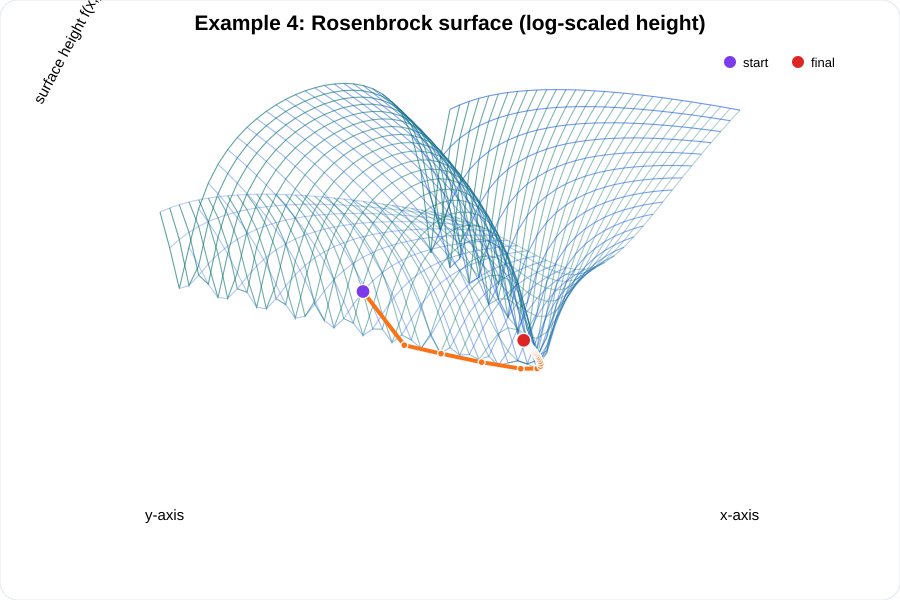

In [7]:
rosenbrock = lambda x, y: (1.0 - x)**2 + 100.0 * (y - x**2)**2
rosenbrock_gradient = lambda x, y: np.array([
    -2.0 * (1.0 - x) - 400.0 * x * (y - x**2),
    200.0 * (y - x**2),
])

rosenbrock_history = gradient_descent_2d(
    rosenbrock, rosenbrock_gradient, initial_xy=(-1.2, 1.0), learning_rate=0.001, steps=8000
)
for step in [0, 1, 10, 100, 1000, 4000, 8000]:
    item = rosenbrock_history[step]
    print(f"step={step:4d} point={item['point']} f={item['value']:.8f} |grad|={np.linalg.norm(item['gradient']):.5f}")

display(SVG(surface_svg(
    rosenbrock, rosenbrock_history, (-2, 2), (-1, 3),
    "Example 4: Rosenbrock surface (log-scaled height)", z_transform=np.log1p,
    grid_size=31
)))


### Why log-transform only the displayed height?

Rosenbrock values vary over a wide range. Plotting $\log(1+f)$ compresses the vertical scale so that both the walls and valley are visible. Because logarithm is monotonic, smaller original values still appear lower. The optimization code nevertheless differentiates and minimizes the original $f$, not its display transform.

### What the surface teaches

- large gradient magnitude does not guarantee that the direction points efficiently along a curved valley;
- one global learning rate must respect the steep direction, slowing movement in flatter directions;
- convergence should be assessed using loss, gradient norm, parameter changes, and validation behavior—not only a fixed number of steps.


## Connection to neural networks

A neural network replaces $(x,y)$ with a parameter vector containing many weights and biases:

$$\boldsymbol\theta=(W_1,b_1,W_2,b_2,\ldots).$$

The training objective is usually an average over examples:

$$L(\boldsymbol\theta)=\frac{1}{N}\sum_{i=1}^N \ell(f_{\boldsymbol\theta}(x^{(i)}),y^{(i)}).$$

Backpropagation computes $\nabla_{\boldsymbol\theta}L$ efficiently. An optimizer then decides how to use that gradient. Plain SGD performs the update shown here; momentum and Adam add state or rescaling but still depend on gradients.

We cannot directly draw a billion-dimensional surface. One- and two-variable plots are slices or analogies that make local slope, curvature, valleys, and learning-rate behavior visible.


## Exercises

1. For Example 1, calculate the first three updates by hand from $w_0=-4$ and $\eta=0.15$.
2. Derive the exact condition for convergence of $f(w)=a(w-c)^2$.
3. Start Example 2 at five evenly spaced positions. Group the final points by basin.
4. Change the coefficient 6 in Example 3 to 1, 20, and 100. Describe the trajectory.
5. For Example 3, compare $\eta=0.02$, $0.12$, and $0.18$.
6. Run Rosenbrock from $(0,0)$ and $(1.5,2)$. Compare steps needed to reach $f<0.01$.
7. Add a stopping rule based on gradient norm and another based on improvement in loss.
8. Implement momentum and overlay its path on the elliptical and Rosenbrock surfaces.
9. Explain why reaching a zero gradient is not sufficient evidence of reaching a global minimum.
10. Relate the narrow Rosenbrock valley to differently scaled neural-network parameters.


## Summary

- Gradient Descent subtracts a learning-rate-scaled derivative or gradient.
- The derivative is a scalar slope; a gradient is a vector of partial derivatives.
- Convex quadratics reveal learning-rate stability clearly.
- Non-convex functions reveal initialization and local-basin dependence.
- Two-dimensional surfaces expose curvature, valleys, and zig-zag trajectories.
- The Rosenbrock function demonstrates why optimization can remain difficult even with one global minimum.
- Backpropagation computes gradients; the optimizer performs parameter updates.
- Neural-network training applies these ideas in far more dimensions.


## Sources

- Cauchy (1847), early formulation of steepest descent.
- Rosenbrock (1960), *An Automatic Method for Finding the Greatest or Least Value of a Function*.
- Goodfellow, Bengio, and Courville (2016), *Deep Learning*, Chapter 8: Optimization for Training Deep Models.
- Boyd and Vandenberghe (2004), *Convex Optimization*, sections on gradient methods.

All functions, optimization implementations, and SVG visualizations in this notebook are self-contained and created for CSS371.
